# DML（Double Machine Learning）：オレンジジュースの値下げ効果

**データ**：シカゴのスーパー Dominick's の冷蔵オレンジジュース（83店舗 × 11ブランド × 週）。
R パッケージ `bayesm` に入っている `orangeJuice` で、出典は Montgomery (1997), *Marketing Science* 16(4)。

**知りたいこと**：値下げすると(D)、販売数(Y)はどれだけ増えるか（価格弾力性）。交絡を取り除いた真の結果が知りたい。


**流れ**
1. データを読む
2. 素朴な回帰（交絡を無視）
3. 手順1・2：LightGBMで「予想」を作り、「残差」を出す
4. 手順3：残差どうしで直線を引く（ATE）
5. DoubleMLパッケージ
6. CATE①：グループごとに直線を分ける
7. CATE②：傾きをEBMで学習する

必要なパッケージ：`pip install numpy pandas matplotlib scikit-learn lightgbm interpret doubleml rdata`

## 因果推論での変数の役割

### 関係図

![因果推論での変数の役割](../images/causal_graph.png)

| 用語 | 記号 | 意味 | このデータの列 |
|---|---|---|---|
| 結果変数（目的変数）outcome | Y | 効果を知りたい結果 | logmove |
| 処置変数 treatment| D | 動かしたときの効果を知りたいもの | log_price |
| 交絡 confounder| X | DとYの両方に影響するもの。取り除かないと効果がずれる | store, brand, week, deal, feat, log_comp_price, 周辺人口の11列 |
| 効果を変える条件 | Z | 効果の大きさが、これによって変わるかを見たいもの（CATE） | INCOME, brand_name |
| 見えていない交絡  | U | DとYの両方に影響するが、データにないもの。DMLでは取り除けない | なし（感度分析で影響を確認する） |
| 効果 | θ | Dを動かしたときにYがどれだけ変わるか。全体平均がATE、条件ごとがCATE | 推定結果 |

### 補足

- **同じ列が2つの役割を持つことがある**：INCOMEとブランドは、交絡X（取り除く対象）でもあり、条件Z（効果の違いを見る切り口）でもある。手順1・2ではXとして予想に使い、手順3ではZとして傾きを分けるのに使う
- **profitは入れない**：利益は、価格と販売数が決まった「あと」に決まる値です。こういう変数をXに入れると、本来の効果まで取り除いてしまい、推定がずれる
- **使わない列**：constant（すべて1）、price1〜price11（log_priceとlog_comp_priceを作るためだけに使用）

## データのカラム定義

Y＝結果、D＝処置、X＝交絡、Z＝CATEの条件

### 元データ（yx）由来

| 列名 | 意味 | 分析での役割 |
|---|---|---|
| store | 店舗番号（83店舗） | X（カテゴリ） |
| brand | ブランド番号（1〜11） | X（カテゴリ） |
| week | 週番号 | X |
| logmove | 販売数量（対数） | **Y** |
| constant | すべて1の列（Rでの回帰用） | 使わない |
| price1〜price11 | その店・その週の各ブランドの価格（1オンスあたりのドル） | log_price と log_comp_price を作るのに使う |
| deal | 店内クーポンの有無 | X |
| feat | チラシ広告への掲載（0〜1） | X |
| profit | 利益 | 使わない |

### 店舗の周辺人口（storedemo）由来

店舗ごとの値なので、同じ店の行はすべて同じ値。比率は0〜1

| 列名 | 意味 | 分析での役割 |
|---|---|---|
| AGE60 | 60歳以上の人の割合 | X |
| EDUC | 大卒の割合 | X |
| ETHNIC | 黒人・ヒスパニックの割合 | X |
| INCOME | 世帯所得の中央値（対数） | X、**Z** |
| HHLARGE | 5人以上の世帯の割合 | X |
| WORKWOM | フルタイムで働く女性の割合 | X |
| HVAL150 | 住宅価値が15万ドル以上の世帯の割合 | X |
| SSTRDIST | 最寄りの大型ディスカウント店までの距離 | X |
| SSTRVOL | 最寄りの大型ディスカウント店に対する、この店の売上の比 | X |
| CPDIST5 | 近くのスーパー5店までの平均距離（マイル） | X |
| CPWVOL5 | 近くのスーパー5店の平均に対する、この店の売上の比 | X |

### 分析内で追加

| 列名 | 意味 | 分析での役割 |
|---|---|---|
| brand_name | ブランド名（例：Tropicana Premium 64oz） | **Z**（グラフ表示にも使う） |
| log_price | 自分のブランドの価格（対数） | **D** |
| log_comp_price | 競合10ブランドの平均価格（対数） | X |


In [1]:
import os, urllib.request, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rdata
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.linear_model import LinearRegression
from lightgbm import LGBMRegressor
from interpret.glassbox import ExplainableBoostingRegressor
import doubleml as dml

warnings.filterwarnings("ignore")
SEED = 0
BLUE, ORANGE, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 11,
})

## 1. ETL

GitHub上のCRANミラーから `orangeJuice.rda` を取ってきて、`rdata` で読み込む

- `yx`：店舗 × ブランド × 週ごとの販売数（`logmove`）、全11ブランドの価格（`price1`〜`price11`）、店内クーポン（`deal`）、チラシ広告（`feat`）
- `storedemo`：店舗の周辺人口の特徴（所得 `INCOME`、大卒比率 `EDUC` など）

In [2]:
URL = "https://raw.githubusercontent.com/cran/bayesm/master/data/orangeJuice.rda"
PATH = "orangeJuice.rda"
if not os.path.exists(PATH):
    urllib.request.urlretrieve(URL, PATH)

oj = rdata.read_rda(PATH)["orangeJuice"]
yx = oj["yx"].astype(float)
demo = oj["storedemo"].astype(float).rename(columns={"STORE": "store"})

df = yx.merge(demo, on="store")
for c in ["store", "brand", "week"]:
    df[c] = df[c].astype(int)

BRANDS = {1: "Tropicana Premium 64oz", 2: "Tropicana Premium 96oz", 3: "Florida's Natural 64oz",
          4: "Tropicana 64oz", 5: "Minute Maid 64oz", 6: "Minute Maid 96oz", 7: "Citrus Hill 64oz",
          8: "Tree Fresh 64oz", 9: "Florida Gold 64oz", 10: "Dominick's 64oz", 11: "Dominick's 128oz"}
df["brand_name"] = df["brand"].map(BRANDS)

# 自社の価格（D）と、競合10ブランドの平均価格（交絡の1つ）
P = df[[f"price{i}" for i in range(1, 12)]].values
idx = df["brand"].values - 1
df["log_price"] = np.log(P[np.arange(len(df)), idx])
others = np.where(np.eye(11, dtype=bool)[idx], np.nan, P)
df["log_comp_price"] = np.log(np.nanmean(others, axis=1))

print(df.shape)
df[["store", "brand_name", "week", "logmove", "log_price", "deal", "feat", "INCOME"]].head()

# yx.to_csv("../data/raw/oj_yx.csv", index=False)
# demo.to_csv("../data/raw/oj_storedemo.csv", index=False)

(106139, 33)


,store,brand_name,week,logmove,log_price,deal,feat,INCOME
0,2,Tropicana Premium 64oz,40,9.018695,-2.805629,1.0,0.0,10.553205
1,2,Tropicana Premium 64oz,46,8.723231,-2.805629,0.0,0.0,10.553205
2,2,Tropicana Premium 64oz,47,8.253228,-2.805629,0.0,0.0,10.553205
3,2,Tropicana Premium 64oz,48,8.987197,-2.805629,0.0,0.0,10.553205
4,2,Tropicana Premium 64oz,50,9.093357,-2.805629,0.0,0.0,10.553205


## 2. 素朴な回帰：交絡を無視するとどうなるか

まずは「価格が安い週ほど売れているか」を、直線で見る。

In [3]:
Y = df["logmove"].values      # 販売数（log）
D = df["log_price"].values    # 価格（log）

naive = np.polyfit(D, Y, 1)[0]
print(f"素朴な回帰の傾き：{naive:.2f}")

素朴な回帰の傾き：-1.51


傾きは約 −1.5 。「価格を1%上げると販売数が1.5%減る」と読める。

でもここには交絡が混ざっている。たとえば、

- **ブランド**：高いブランド（Tropicana Premium）はもともとよく売れる → 「高いのに売れる」ように見えて、効果が小さく見える
- **広告・クーポン**：値下げの週はチラシにも載りやすく、チラシ自体でも売れる
- **店舗**：客層によって、価格も販売数も違う

線形回帰に交絡を入れて比べてる（店舗とブランドはダミー変数に変換）。

In [4]:
demo_cols = ["AGE60", "EDUC", "ETHNIC", "INCOME", "HHLARGE", "WORKWOM",
             "HVAL150", "SSTRDIST", "SSTRVOL", "CPDIST5", "CPWVOL5"]
x_cols = ["store", "brand", "week", "deal", "feat", "log_comp_price"] + demo_cols

X_lin = pd.get_dummies(df[x_cols], columns=["store", "brand"], drop_first=True).astype(float)
lin = LinearRegression().fit(np.column_stack([D, X_lin]), Y)
print(f"線形回帰（交絡を入れる）の傾き：{lin.coef_[0]:.2f}")

線形回帰（交絡を入れる）の傾き：-3.10


交絡を入れると傾きが大きく変わる。ただ、線形回帰だと「交絡は足し算で直線的に効く」という前提を置いている。
DMLは、この「交絡の影響」の部分をMLで柔軟に学習。

## 3. 手順1・2：「予想」を作り、「残差」を出す

- **手順1**：交絡Xだけから、販売数を予想する → 残差（意外な販売） = 実際 − 予想
- **手順2**：交絡Xだけから、価格を予想する → 残差（意外な価格） = 実際 − 予想

どちらもLightGBMで、**out-of-fold** で予想。
5つに分けて、各ブロックの予想は「そのブロックを学習に使っていないモデル」で出す。

店舗とブランドはカテゴリ変数として入れるので、「この店のこのブランドは普段このくらい売れる、このくらいの価格」という部分も予想に含まれる。

In [5]:
X = df[x_cols].copy()
X["store"] = X["store"].astype("category")
X["brand"] = X["brand"].astype("category")

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
lgbm = LGBMRegressor(n_estimators=500, learning_rate=0.05, num_leaves=63,
                     random_state=SEED, verbose=-1)

Y_hat = cross_val_predict(lgbm, X, Y, cv=cv)   # 手順1：販売数の予想
D_hat = cross_val_predict(lgbm, X, D, cv=cv)   # 手順2：価格の予想

Y_res = Y - Y_hat    # 意外な販売
D_res = D - D_hat    # 意外な価格

r2 = lambda y, r: 1 - r.var() / y.var()
print(f"販売数の予想の当てはまり（R2）：{r2(Y, Y_res):.3f}")
print(f"価格の予想の当てはまり（R2）  ：{r2(D, D_res):.3f}")

販売数の予想の当てはまり（R2）：0.881
価格の予想の当てはまり（R2）  ：0.973


価格はほとんど（R2 ≈ 0.97）交絡から予想できている。DMLが使うのは、残りの数％の「予想外の値下げ・値上げ」のみ。
この「残差（意外な価格）」が十分にばらついていないと推定できないので、R2が1に近すぎないか確認する。

## 4. 手順3：残差回帰（ATE）

傾き = Σ(意外な価格 × 意外な販売) ÷ Σ(意外な価格²) 。

標準誤差は、同じ店舗のデータは似た動きをする（独立ではない）ので、**店舗ごとのクラスタ** で計算。

In [6]:
def residual_slope(d_res, y_res, clusters):
    # 意外どうしの傾きと、クラスタ頑健な標準誤差
    theta = (d_res * y_res).sum() / (d_res ** 2).sum()
    err = y_res - theta * d_res
    score_by_cluster = pd.Series(d_res * err).groupby(np.asarray(clusters)).sum().values
    se = np.sqrt((score_by_cluster ** 2).sum()) / (d_res ** 2).sum()
    return theta, se

theta, se = residual_slope(D_res, Y_res, df["store"])
print(f"DMLの推定（ATE）：{theta:.2f}  95%区間 [{theta - 1.96*se:.2f}, {theta + 1.96*se:.2f}]")

DMLの推定（ATE）：-2.90  95%区間 [-3.10, -2.70]


「価格を1%上げると、販売数が約2.9%減る」という結果。素朴な回帰（約 −1.5）は効果をかなり小さく見積もっていた。

手順3をグラフで見てみる。左が素朴な回帰（実際の価格 vs 実際の販売）、右がDML（意外な価格 vs 意外な販売）。

点が多すぎるので、横軸を20等分した区間ごとの平均であらわす。

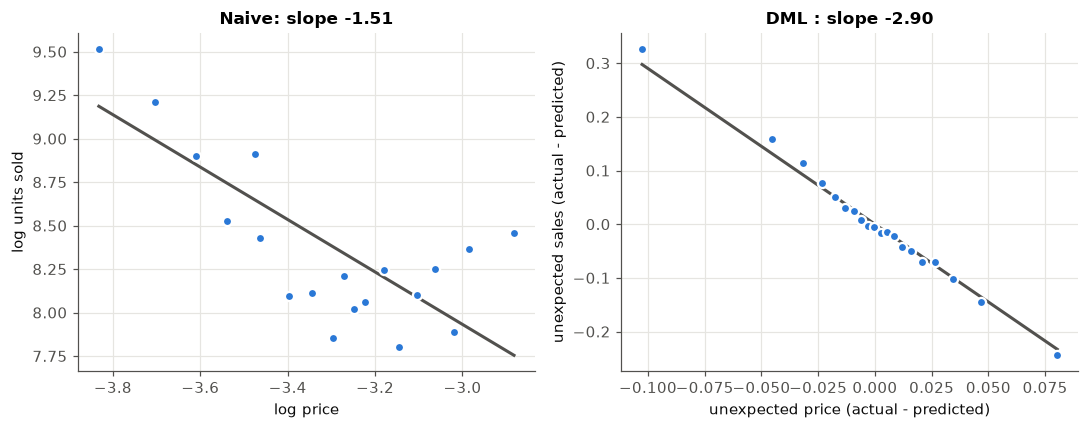

In [8]:
def binned(x, y, n=20):
    b = pd.qcut(x, n, duplicates="drop")
    g = pd.DataFrame({"x": x, "y": y}).groupby(b, observed=True).mean()
    return g["x"].values, g["y"].values

fig, axes = plt.subplots(1, 2, figsize=(10, 4))

bx, by = binned(D, Y)
axes[0].scatter(bx, by, s=36, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
xs = np.linspace(bx.min(), bx.max(), 2)
axes[0].plot(xs, np.polyval(np.polyfit(D, Y, 1), xs), color=MUTED, lw=2)
axes[0].set(title=f"Naive: slope {naive:.2f}", xlabel="log price", ylabel="log units sold")

bx, by = binned(D_res, Y_res)
axes[1].scatter(bx, by, s=36, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
xs = np.linspace(bx.min(), bx.max(), 2)
axes[1].plot(xs, theta * xs, color=MUTED, lw=2)
axes[1].set(title=f"DML : slope {theta:.2f}",
            xlabel="unexpected price (actual - predicted)",
            ylabel="unexpected sales (actual - predicted)")
plt.tight_layout()
plt.show()

**残差回帰がきれいな直線となった理由**
- 1点あたりのデータが多い：各点は約5,300行の平均。一方、横軸の端から端までで、販売数は約0.55（約55%）も動き、ブレに比べてずっと大きいので、点はほぼ線の上に乗った
- 価格と販売数がlogどうしで直線の関係：「価格が1%変わると販売数が一定の%変わる」という関係がよく当てはまるデータのため（オレンジジュースのデータは、価格弾力性の教科書的な例としてよく使われる）
- 交絡が取り除かれている：ブランドや店舗の違いで点が散らばる要因がなくなっているため

**残差回帰が直線にならない場合の例**
- データが少ない：1点あたりの件数が少ないと、点がばらつく
- 関係が曲がっている：飽和（打てば打つほど効きが落ちる）や閾値があると、点が曲線を描く（DMの量のような処置変数では、むしろ曲がるのが普通）
- 残差がほとんどない、または記録ミスが多い：直線が寝て（傾きが0に近づいて）見える

## 5. DoubleML

手計算と同じことを、DoubleMLで実装。
同じ予想モデル・同じfold数なら、ほぼ同じ値になるはず。

DoubleMLはデータをnumpyに変換するので、店舗とブランドはダミー変数。

In [9]:
dml_df = pd.concat([X_lin, df[["logmove", "log_price"]]], axis=1)
dml_df.columns = [str(c) for c in dml_df.columns]
data = dml.DoubleMLData(dml_df, y_col="logmove", d_cols="log_price",
                        x_cols=[str(c) for c in X_lin.columns])

model = dml.DoubleMLPLR(data, ml_l=LGBMRegressor(n_estimators=500, learning_rate=0.05,
                                                   num_leaves=63, random_state=SEED, verbose=-1),
                        ml_m=LGBMRegressor(n_estimators=500, learning_rate=0.05,
                                           num_leaves=63, random_state=SEED, verbose=-1),
                        n_folds=5)
model.fit()
print(model.summary.round(3))

            coef  std err      t  P>|t|  2.5 %  97.5 %
log_price -2.732    0.049 -56.14    0.0 -2.828  -2.637


推定値は手計算と近い値（完全には一致しないのは、foldの切り方と、店舗を「カテゴリ変数」ではなく「ダミー変数」で入れているため予想モデルの学習が少し変わるから）

標準誤差はDoubleMLのほうが小さく出る（各行を独立として計算しているためで、店舗クラスタを考えた手計算のほうが慎重な（幅の広い）値のためと考えられる）

## 6. CATE①：グループごとに直線を分ける

手順1・2の「予想」はそのまま使い、**手順3の直線だけ** をグループごとに引く。

まずは店舗の周辺所得（`INCOME`）を3つに分ける。

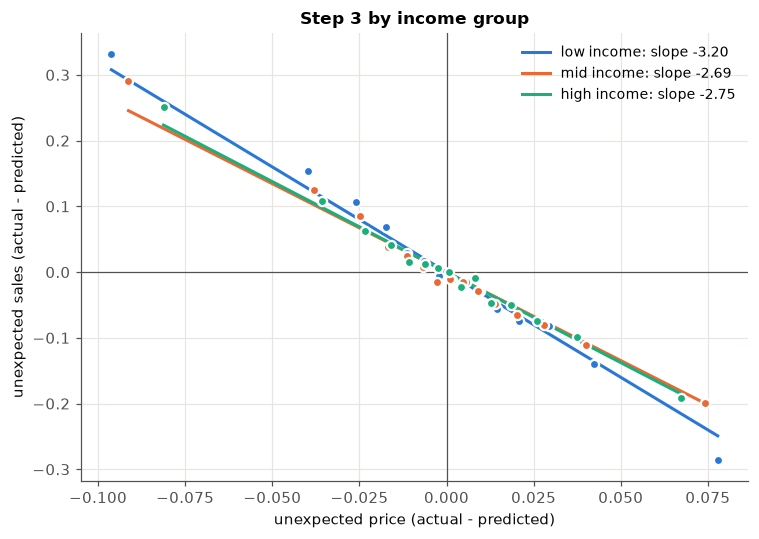

In [10]:
income_group = pd.qcut(df["INCOME"], 3, labels=["low income", "mid income", "high income"])

rows = []
for g in income_group.cat.categories:
    m = (income_group == g).values
    t, s = residual_slope(D_res[m], Y_res[m], df["store"][m])
    rows.append({"group": g, "stores": df["store"][m].nunique(), "slope": t,
                 "ci_low": t - 1.96 * s, "ci_high": t + 1.96 * s})
cate_income = pd.DataFrame(rows)
cate_income.round(2)

AQUA = "#1baf7a"
colors = {"low income": BLUE, "mid income": ORANGE, "high income": AQUA}

fig, ax = plt.subplots(figsize=(7, 5))
for _, r in cate_income.iterrows():
    g = r["group"]
    m = (income_group == g).values
    bx, by = binned(D_res[m], Y_res[m], n=15)          # グループごとに15区間の平均
    ax.scatter(bx, by, s=36, color=colors[g], edgecolor="white", linewidth=1.5, zorder=3)
    xs = np.array([bx.min(), bx.max()])
    ax.plot(xs, r["slope"] * xs, color=colors[g], lw=2,
            label=f'{g}: slope {r["slope"]:.2f}')
ax.axhline(0, color=MUTED, lw=0.8)
ax.axvline(0, color=MUTED, lw=0.8)
ax.legend(frameon=False, fontsize=9, loc="upper right")
ax.set(title="Step 3 by income group",
       xlabel="unexpected price (actual - predicted)",
       ylabel="unexpected sales (actual - predicted)")
plt.tight_layout()
plt.show()

所得の低い地域の店は、他より価格に敏感（傾きがより大きなマイナス）という結果。（中所得と高所得の差ははっきりしない）

次に、ブランドごとに分ける。

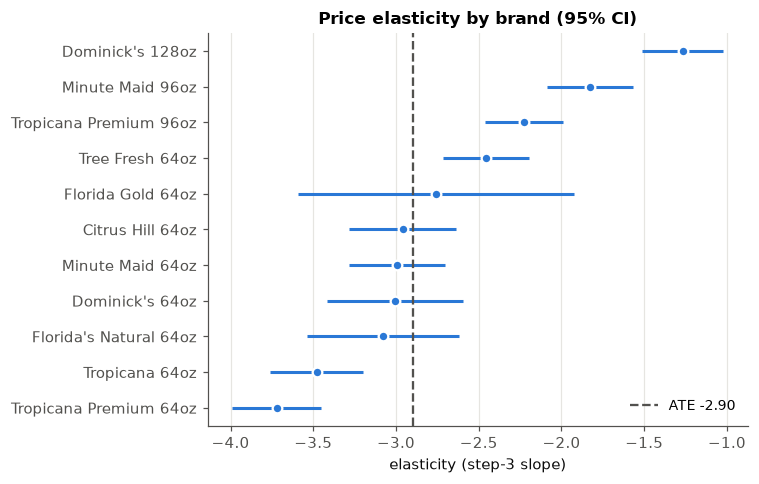

,brand,slope,ci_low,ci_high
0,Tropicana Premium 64oz,-3.72,-3.99,-3.45
1,Tropicana 64oz,-3.48,-3.76,-3.20
2,Florida's Natural 64oz,-3.08,-3.54,-2.62
3,Dominick's 64oz,-3.01,-3.42,-2.59
4,Minute Maid 64oz,-2.99,-3.29,-2.70
5,Citrus Hill 64oz,-2.96,-3.28,-2.64
6,Florida Gold 64oz,-2.76,-3.59,-1.92
7,Tree Fresh 64oz,-2.46,-2.72,-2.20
8,Tropicana Premium 96oz,-2.23,-2.46,-1.99
9,Minute Maid 96oz,-1.83,-2.08,-1.57


In [35]:
rows = []
for b, name in BRANDS.items():
    m = (df["brand"] == b).values
    t, s = residual_slope(D_res[m], Y_res[m], df["store"][m])
    rows.append({"brand": name, "slope": t, "ci_low": t - 1.96 * s, "ci_high": t + 1.96 * s})
cate_brand = pd.DataFrame(rows).sort_values("slope").reset_index(drop=True)

fig, ax = plt.subplots(figsize=(7, 4.5))
yy = np.arange(len(cate_brand))
ax.hlines(yy, cate_brand["ci_low"], cate_brand["ci_high"], color=BLUE, lw=2)
ax.scatter(cate_brand["slope"], yy, s=40, color=BLUE, edgecolor="white", linewidth=1.5, zorder=3)
ax.axvline(theta, color=MUTED, lw=1.5, ls="--", label=f"ATE {theta:.2f}")
ax.legend(frameon=False, fontsize=9, loc="lower right")
ax.set_yticks(yy, cate_brand["brand"])
ax.set(title="Price elasticity by brand (95% CI)", xlabel="elasticity (step-3 slope)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()
cate_brand.round(2)

ブランドによって効き方がかなり違う。大容量（96oz・128oz）は、どのブランドでも64ozより価格に鈍感

次に、周辺所得水準に応じた価格弾力性をスプラインに変換

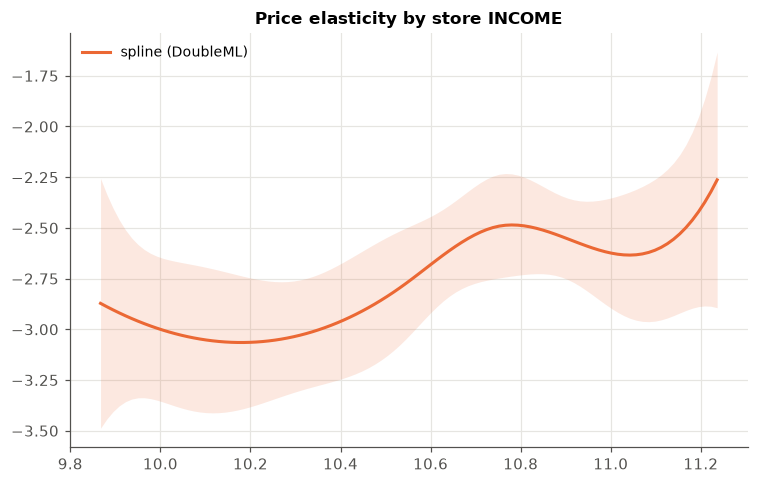

In [15]:
import patsy
feature = "INCOME"

# 所得をスプライン（なめらかな曲線の部品5本）に変換して、効果を推定
spline = patsy.dmatrix("bs(" + feature + ", df=5, degree=3)", df[[feature]], return_type="dataframe")
cate_spline = model.cate(spline)

# 所得の範囲を100点に分けて、各点での効果と信頼区間を出す
grid = pd.DataFrame({feature: np.linspace(df[feature].min(), df[feature].max(), 100)})
grid_basis = patsy.build_design_matrices([spline.design_info], grid, return_type="dataframe")[0]
ci = cate_spline.confint(grid_basis, joint=True, level=0.95, n_rep_boot=500)

# 描画
fig, ax = plt.subplots(figsize=(7, 4.5))
# plot_shape(ebm, Z, "INCOME", ax)
ax.fill_between(grid[feature], ci["2.5 %"], ci["97.5 %"], color=ORANGE, alpha=0.15, lw=0)
ax.plot(grid[feature], ci["effect"], color=ORANGE, lw=2)
ax.legend(handles=[
    #plt.Line2D([], [], color=BLUE, lw=2, label="EBM"),
    plt.Line2D([], [], color=ORANGE, lw=2, label="spline (DoubleML)")
    ],
    frameon=False, fontsize=9, loc="upper left")
ax.set(title=f"Price elasticity by store {feature}")
plt.tight_layout()
plt.show()

周辺所得が低い地域では価格弾力性が高く、周辺所得があがると価格弾力性は下がる傾向

**memo**
- 手順6でINCOMEを3つに分けたり、ブランドごとに直線を引いたりしたのは、GATE
- EBMやスプラインで、INCOMEやWORKWOMに沿ったカーブを描いたのは、CATE


## 7. CATE②：傾きをEBMで学習する

最後の回帰「意外な販売 ≈ 傾き(条件) × 意外な価格」は、次のように書き換えられる。

- 目的変数：意外な販売 ÷ 意外な価格
- 重み：意外な価格²
- 入力：効果を変えそうな条件 Z

この重みつき回帰をEBMで解くと、**「条件によって効き目がどう変わるか」のShape** が見える。
（普段のEBMのShapeは「予測値の形」ですが、ここでは「価格弾力性の形」）

ポイント
- 意外な価格がほぼ0の行は、割り算が暴れるので除きます（重みもほぼ0なので影響は小さい）
- Zは「効き目が変わりそう」と考える変数を自分で選びます。ここでは所得とブランド
- 所得は店舗単位の値（83店舗分しかない）なので、細かく分けすぎないよう `max_bins` を小さくする

In [11]:
Z = df[["INCOME", "brand_name"]]
keep = np.abs(D_res) > 0.005

ebm = ExplainableBoostingRegressor(
    feature_types=["continuous", "nominal"],
    interactions=0, max_bins=16, smoothing_rounds=500, random_state=SEED)
ebm.fit(Z[keep], (Y_res / D_res)[keep], sample_weight=(D_res ** 2)[keep])

cate_ebm = ebm.predict(Z)
avg = (cate_ebm * D_res ** 2).sum() / (D_res ** 2).sum()
print(f"EBMの切片（平均的な効果）：{ebm.intercept_:.2f}")
print(f"重みつき平均：{avg:.2f}   ← ATE {theta:.2f} とほぼ一致するはず")

EBMの切片（平均的な効果）：-2.90
重みつき平均：-2.90   ← ATE -2.90 とほぼ一致するはず


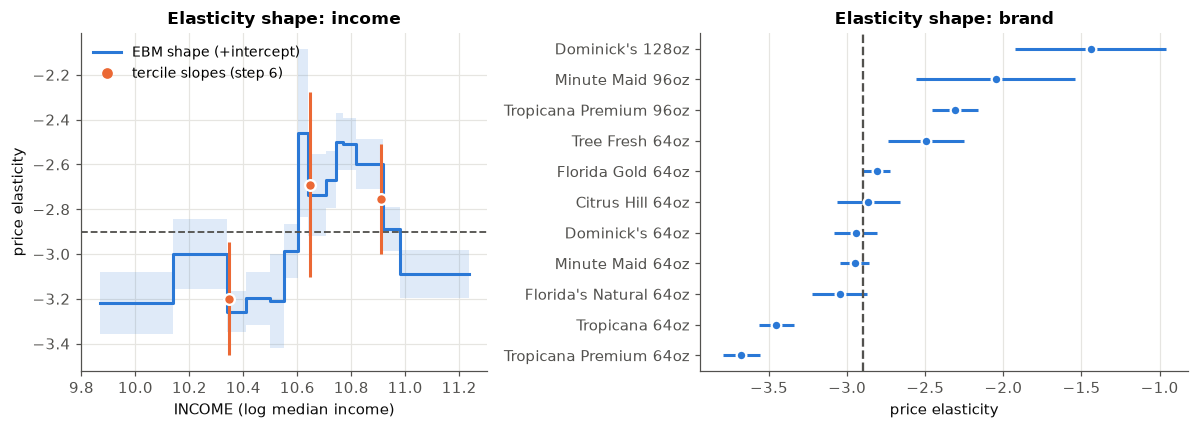

In [12]:
def shape(ebm, name):
    i = ebm.term_names_.index(name)
    s = ebm.term_scores_[i][1:-1]            # 先頭と末尾（欠損・未知）を除く
    sd = ebm.standard_deviations_[i][1:-1]
    return s, sd

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.2]})

# 所得のShape
cuts = ebm.bins_[0][0]
edges = np.r_[df["INCOME"].min(), cuts, df["INCOME"].max()]
s, sd = shape(ebm, "INCOME")
x = np.repeat(edges, 2)[1:-1]
yv = np.repeat(s + ebm.intercept_, 2)
ysd = np.repeat(sd, 2)
axes[0].fill_between(x, yv - 1.96 * ysd, yv + 1.96 * ysd, color=BLUE, alpha=0.15, lw=0)
axes[0].plot(x, yv, color=BLUE, lw=2)
for _, r in cate_income.iterrows():
    m = (income_group == r["group"]).values
    xm = df["INCOME"][m].median()
    axes[0].errorbar(xm, r["slope"], yerr=[[r["slope"] - r["ci_low"]], [r["ci_high"] - r["slope"]]],
                     fmt="o", color=ORANGE, ms=7, mec="white", mew=1.5, lw=2, capsize=0, zorder=4)
axes[0].set(title="Elasticity shape: income", xlabel="INCOME (log median income)",
            ylabel="price elasticity")
axes[0].legend(handles=[plt.Line2D([], [], color=BLUE, lw=2, label="EBM shape (+intercept)"),
                        plt.Line2D([], [], color=ORANGE, marker="o", lw=0, label="tercile slopes (step 6)")],
               frameon=False, fontsize=9, loc="upper left")
axes[0].axhline(ebm.intercept_, color=MUTED, lw=1.2, ls="--")

# ブランドのShape
i = ebm.term_names_.index("brand_name")
names = list(ebm.bins_[1][0].keys())
s, sd = shape(ebm, "brand_name")
order = np.argsort(s)
yy = np.arange(len(names))
axes[1].hlines(yy, (s - 1.96 * sd)[order] + ebm.intercept_, (s + 1.96 * sd)[order] + ebm.intercept_,
               color=BLUE, lw=2)
axes[1].scatter(s[order] + ebm.intercept_, yy, color=BLUE, s=40, edgecolor="white", linewidth=1.5, zorder=3)
axes[1].axvline(ebm.intercept_, color=MUTED, lw=1.5, ls="--")
axes[1].set_yticks(yy, np.array(names)[order])
axes[1].set(title="Elasticity shape: brand", xlabel="price elasticity")
axes[1].grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

**読み方**
- 左：周辺所得ごとの価格弾力性。オレンジの点は、6でやった「3グループに分けて直線を引いた」結果。EBMの曲線と大きく食い違っていなければ、2つのやり方が同じ傾向を捉えていると言える
- 両端（周辺所得が特に低い・高い店）は店舗数が少ないので、形を読みすぎないようにする
- 右：ブランドごとの価格弾力性（所得の影響を調整した後）。6の直線を分けた結果とほぼ同じ並び
- EBMは足し算のモデルなので、Zに大卒比率など所得と相関する変数を足すと、所得のShapeは「大卒比率をそろえたうえでの所得の違い」という意味に変わり、形も変わる
- 帯・横線はEBM内部のバギングから出したばらつき。手順1・2の予想の不確かさや店舗のクラスタは含んでいないので、本当の信頼区間より狭めに出る。きちんと幅を出すなら、店舗単位のブートストラップで手順1〜3をやり直す必要がある

**価格弾力性**
- 絶対値が大きい（例：−3.6）：価格に敏感。少し値下げすると、販売数が大きく増える
- 絶対値が小さい（例：−1.3）：価格に鈍感。値下げしても、販売数はあまり増えない

## 8. まとめ
| やり方 | 価格弾力性 |
|---|---|
| 素朴な回帰 | 約 −1.5 |
| DML（ATE） | 約 −2.9 |

- **交絡の入れ忘れ**：DMLが消せるのはXに入れた交絡だけ。たとえば「需要が高まりそうな週を店が予想して値段を上げた」なら、その情報はXにないので残る
- **log-logなので弾力性**：傾きは「価格1%あたりの販売の%変化」。お金のROIにするには、販売数・価格・コストを掛け直す必要がある

## 8. MEMO

### Shape研究

In [29]:
Z = df[["INCOME", "brand_name", "AGE60", "EDUC", "ETHNIC", "HHLARGE", "WORKWOM",
         "HVAL150", "SSTRDIST", "SSTRVOL", "CPDIST5", "CPWVOL5", "week", "deal", "feat", "log_comp_price"]]
keep = np.abs(D_res) > 0.005

ebm = ExplainableBoostingRegressor(
    # feature_types=["continuous", "nominal"],
    interactions=0, max_bins=16, smoothing_rounds=500, random_state=SEED)
ebm.fit(Z[keep], (Y_res / D_res)[keep], sample_weight=(D_res ** 2)[keep])

cate_ebm = ebm.predict(Z)
avg = (cate_ebm * D_res ** 2).sum() / (D_res ** 2).sum()
print(f"EBMの切片（平均的な効果）：{ebm.intercept_:.2f}")
print(f"重みつき平均：{avg:.2f}   ← ATE {theta:.2f} とほぼ一致するはず")

EBMの切片（平均的な効果）：-2.90
重みつき平均：-2.90   ← ATE -2.90 とほぼ一致するはず


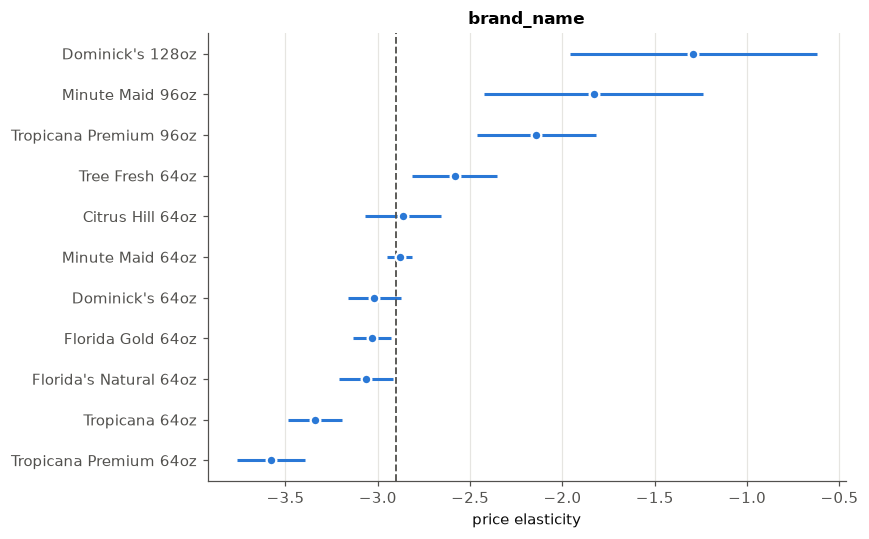

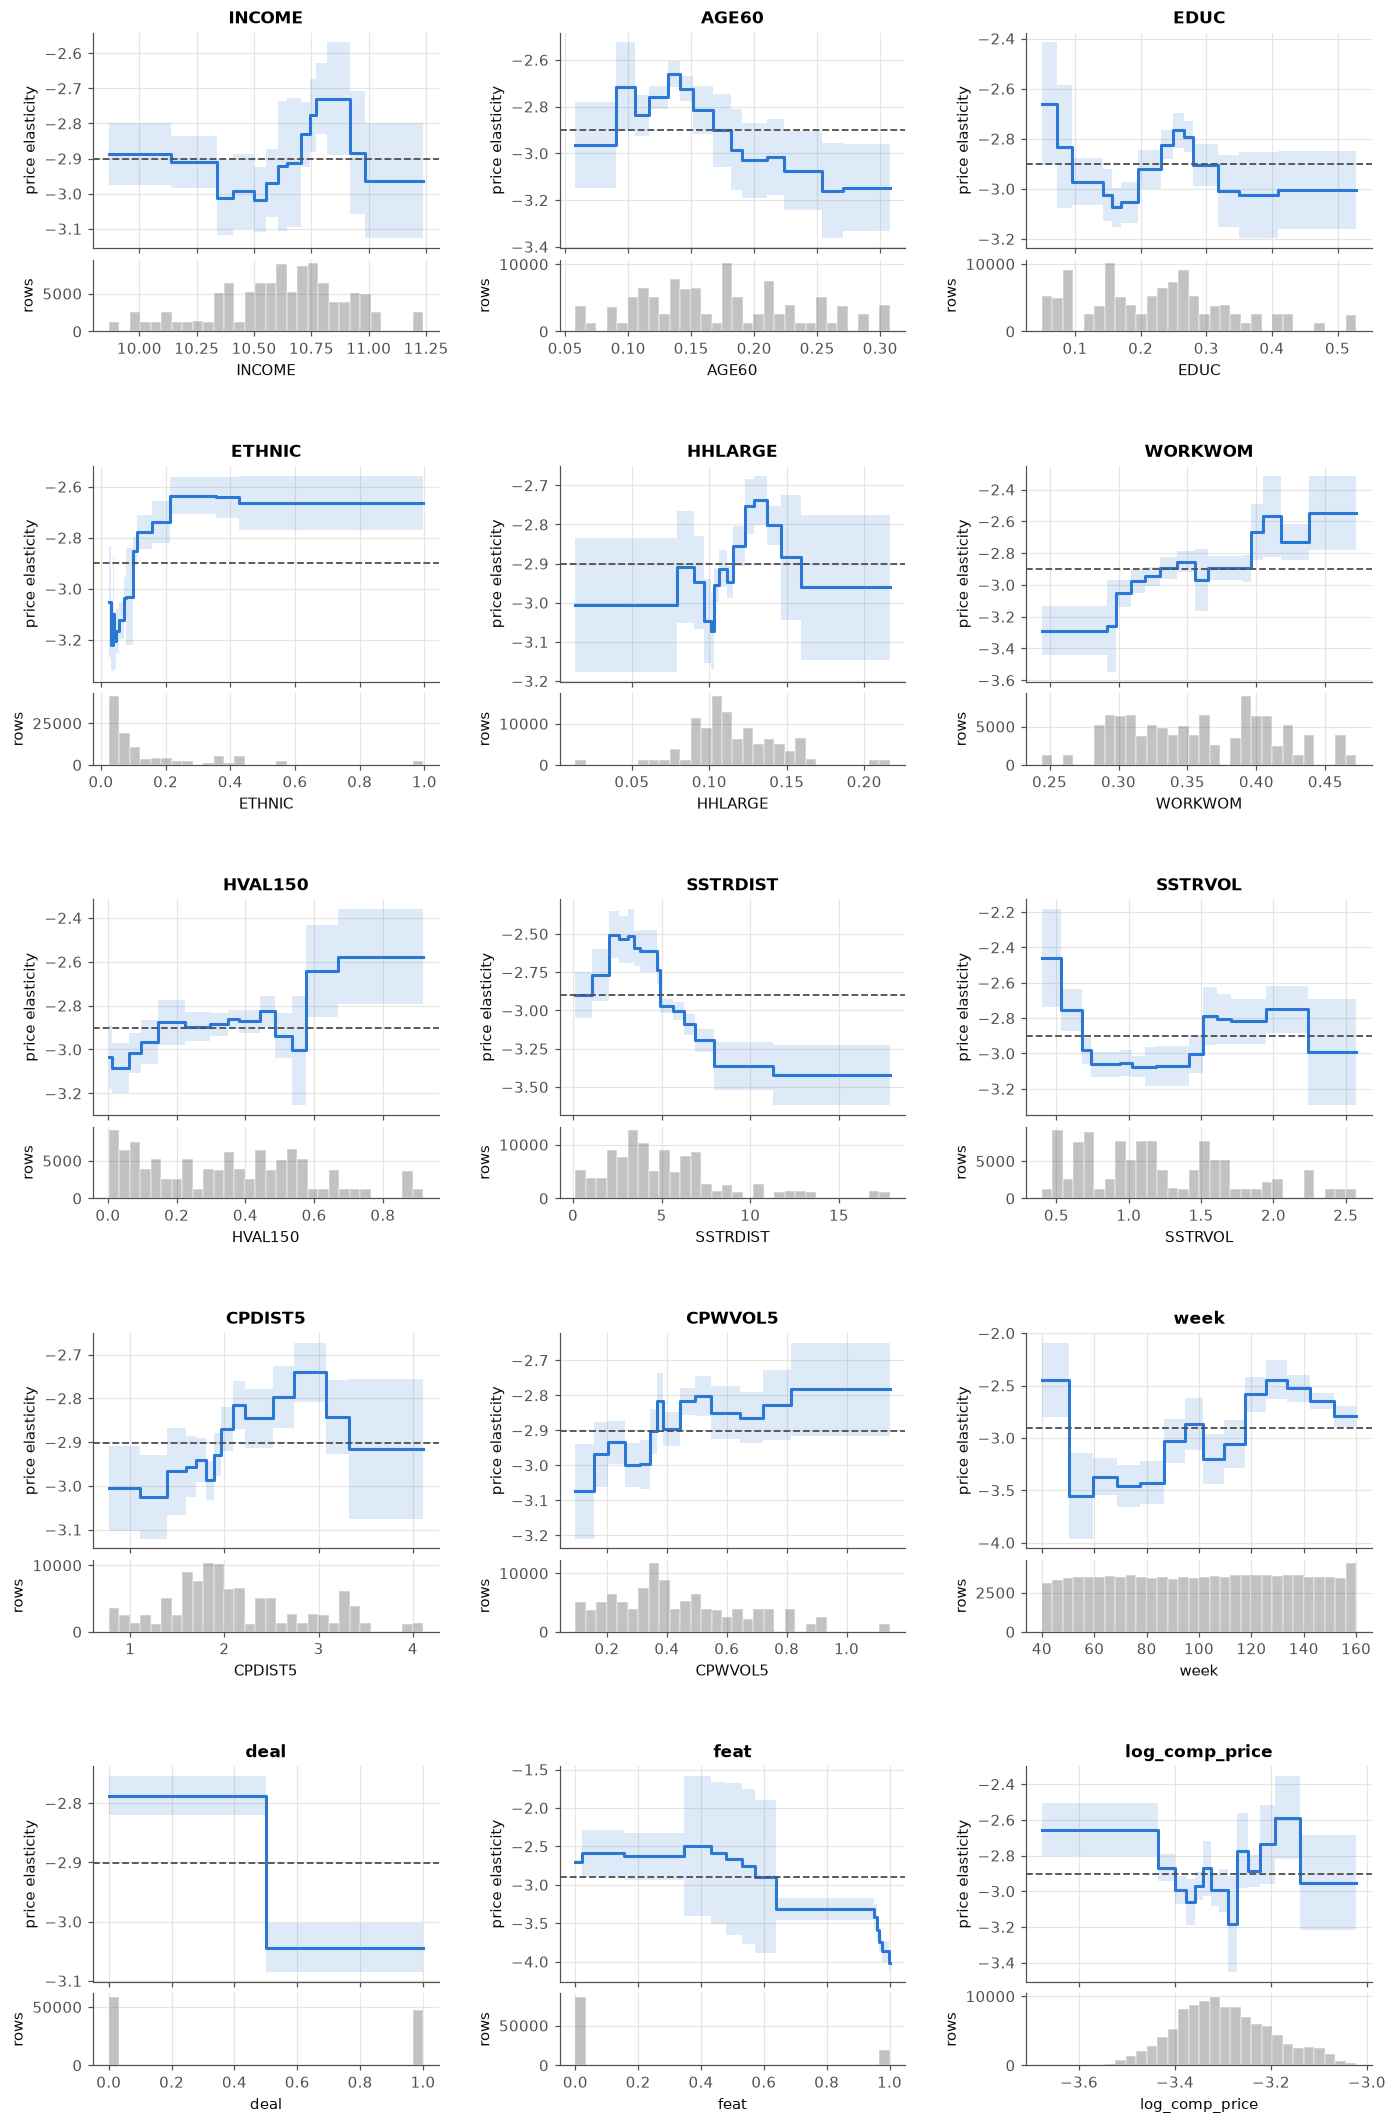

In [30]:
def is_category(ebm, name):
    i = ebm.term_names_.index(name)
    return isinstance(ebm.bins_[i][0], dict)

def draw_count(ebm, Z, name, ax, n_bars=30):
    # 渡された枠に、データ件数の棒グラフを描く
    if is_category(ebm, name):                        # カテゴリ（ブランドなど）は件数がほぼ同じなので省略
        ax.axis("off")
        return
    counts, edges = np.histogram(Z[name], bins=n_bars)
    ax.bar(edges[:-1], counts, width=np.diff(edges), align="edge",
           color=MUTED, alpha=0.35, edgecolor="white")
    ax.set(ylabel="rows", xlabel=name)

# ブランドだけ単独で表示
fig, ax = plt.subplots(figsize=(8, 5))
plot_shape(ebm, Z, "brand_name", ax)
plt.tight_layout()
plt.show()

# 残りの連続変数を並べて表示（各変数：上にShape、下に件数）
names = [n for n in ebm.term_names_ if not is_category(ebm, n)]
ncol = 3
nrow = int(np.ceil(len(names) / ncol))
fig = plt.figure(figsize=(5 * ncol, 4.8 * nrow))
outer = fig.add_gridspec(nrow, ncol, hspace=0.45, wspace=0.35)

for k, name in enumerate(names):
    r, c = divmod(k, ncol)
    inner = outer[r, c].subgridspec(2, 1, height_ratios=[3, 1], hspace=0.08)
    ax = fig.add_subplot(inner[0])
    ax_n = fig.add_subplot(inner[1], sharex=ax)
    plot_shape(ebm, Z, name, ax)
    draw_count(ebm, Z, name, ax_n)
    ax.set_xlabel("")
    ax.tick_params(labelbottom=False)

plt.show()

### EBM vs spline

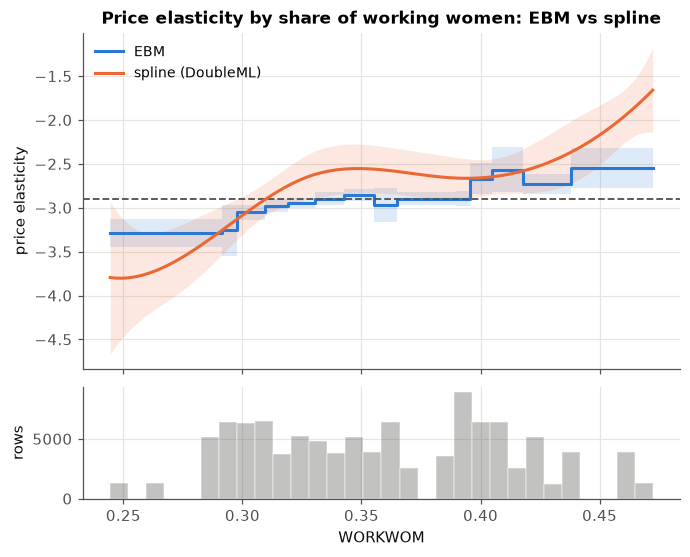

In [31]:
def plot_ebm_vs_spline(ebm, model, Z, name, title=None, df_spline=5):
    
    # DoubleMLでスプラインのCATEを計算
    spline = patsy.dmatrix(f"bs({name}, df={df_spline}, degree=3)", Z[[name]], return_type="dataframe")
    cate_spline = model.cate(spline)
    grid = pd.DataFrame({name: np.linspace(Z[name].min(), Z[name].max(), 100)})
    grid_basis = patsy.build_design_matrices([spline.design_info], grid, return_type="dataframe")[0]
    ci = cate_spline.confint(grid_basis, joint=True, level=0.95, n_rep_boot=500)

    # 上：EBMとスプライン、下：データ件数
    fig, (ax, ax_n) = plt.subplots(2, 1, figsize=(7, 5.5), sharex=True,
                                   gridspec_kw={"height_ratios": [3, 1], "hspace": 0.08})
    plot_shape(ebm, Z, name, ax)
    ax.fill_between(grid[name], ci["2.5 %"], ci["97.5 %"], color=ORANGE, alpha=0.15, lw=0)
    ax.plot(grid[name], ci["effect"], color=ORANGE, lw=2)
    ax.legend(handles=[plt.Line2D([], [], color=BLUE, lw=2, label="EBM"),
                       plt.Line2D([], [], color=ORANGE, lw=2, label="spline (DoubleML)")],
              frameon=False, fontsize=9, loc="upper left")
    ax.set(title=title or f"Price elasticity by {name}: EBM vs spline", xlabel="")
    ax.tick_params(labelbottom=False)
    draw_count(ebm, Z, name, ax_n)
    plt.tight_layout()
    return fig

plot_ebm_vs_spline(ebm, model, Z, "WORKWOM",
                   title="Price elasticity by share of working women: EBM vs spline")
plt.show()

### どの交絡が特に効いているか
- 交絡のグループを1つずつXから外してDMLをやり直し、推定値がどれだけ動くかを見る
- 大きく動くほど、その交絡を入れておくことが重要

In [32]:
groups = {
    "店舗 store": ["store"],
    "周辺人口 demographics": demo_cols,
    "ブランド brand": ["brand"],
    "時期 week": ["week"],
    "販促 deal, feat": ["deal", "feat"],
    "競合価格 log_comp_price": ["log_comp_price"],
}

rows = []
for name, cols in groups.items():
    keep_cols = [c for c in x_cols if c not in cols]
    y_r = Y - cross_val_predict(lgbm, X[keep_cols], Y, cv=cv)
    d_r = D - cross_val_predict(lgbm, X[keep_cols], D, cv=cv)
    t, _ = residual_slope(d_r, y_r, df["store"])
    rows.append({"外した交絡": name, "推定": round(t, 2), "変化": round(t - theta, 2)})

pd.DataFrame(rows).sort_values("変化", key=abs, ascending=False)

,外した交絡,推定,変化
2,ブランド brand,-1.66,1.24
4,"販促 deal, feat",-4.05,-1.15
0,店舗 store,-2.54,0.36
3,時期 week,-3.18,-0.28
5,競合価格 log_comp_price,-2.77,0.13
1,周辺人口 demographics,-2.80,0.10


- ブランドを外すと効果が小さく見える：高いブランドほどもともとよく売れるので、「高くても売れる」ように見えてしまう
- 販促を外すと効果が大きく見える：値下げの週はチラシやクーポンも重なるので、その売上増まで値下げの効果に数えてしまう